# Introduction to Google Colab & Colab Enterprise (through **MonarchSphere**)

**Learning goals:**

(1) Understand Google Colab basics

(2) Inspect the CPU/GPU runtime

(3) Train a small neural network with PyTorch

(4) Evaluate predictions

**Before you start**

If you want to select a GPU runtime before running the notebook.

- **Google Colab (Free tier):** Go to Runtime → Change runtime type → Hardware accelerator → GPU (T4), then click `Save`.
- **Google Colab Enterprise:** Go to Connect → Connect to a runtime → Connect to an existing Runtime → Select a GPU template, select an available GPU (for example, L4 if available), then click `Connect`.

**Agenda**
| Section |
|---|
| 0. Google Colab Basics |
| 1. Setting up Environment |
| 2. Multi-Layer Perceptron (MLP) with PyTorch |

<br>
<br>
Author: __Rochana R. Obadage__<br><br>

# 0. Google Colab Basics

## 0.1. What is Colab?

Colab, or "Colaboratory", allows you to write and execute Python in your browser, with
- Zero configuration required
- Access to GPUs free of charge
- Easy sharing

Whether you're a **student**, a **data scientist** or an **AI researcher**, Colab can make your work easier. Watch [Introduction to Colab](https://www.youtube.com/watch?v=inN8seMm7UI) to learn more!

## 0.2. Ways to start colab

*   Google Search "Google Colab" and save a copy
*   Upload the .ipynb file to google drive
    - open-with --> connect more-apps --> Colaboratory

## 0.3. Sharing the notebook with others



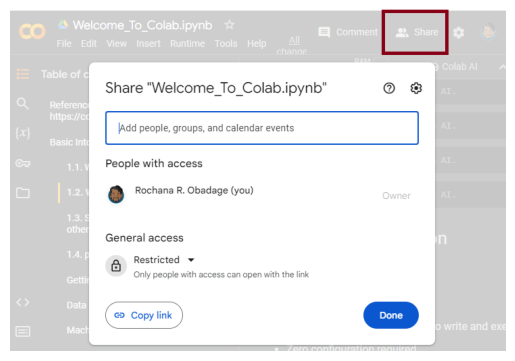

In [ ]:
# import matplotlib.pyplot as plt
# import matplotlib.image as mpimg

# img = mpimg.imread('colab-intro/Sharing.PNG')
# plt.imshow(img)
# plt.axis('off')
# plt.show()

## 0.4. python env

In [ ]:
!python --version

Python 3.13.18


## 0.5. subshell "!" and magic "%" commands

https://stackoverflow.com/questions/60794530/in-jupyter-notebooks-on-google-colab-whats-the-difference-between-using-and

In [ ]:
!pwd
# /content

!cd sample_data/
!pwd
# /content

%cd sample_data/
!pwd
# /content/sample_data"

/content
/content
/content/sample_data
/content/sample_data


## 0.6. Getting started

The document you are reading is not a static web page, but an interactive environment called a **Colab notebook** that lets you write and execute code. For example, here is a **code cell** with a short Python script that computes a value, stores it in a variable, and prints the result:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

To execute the code in the above cell, select it with a click and then either press the play button to the left of the code, or use the keyboard shortcut "Command/Ctrl+Enter". To edit the code, just click the cell and start editing.

Variables that you define in one cell can later be used in other cells:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

Colab notebooks allow you to combine **executable code** and **rich text** in a single document, along with **images**, **HTML**, **LaTeX** and more. When you create your own Colab notebooks, they are stored in your Google Drive account. You can easily share your Colab notebooks with co-workers or friends, allowing them to comment on your notebooks or even edit them. To learn more, see [Overview of Colab](/notebooks/basic_features_overview.ipynb). To create a new Colab notebook you can use the File menu above, or use the following link: [create a new Colab notebook](http://colab.research.google.com#create=true).

Colab notebooks are Jupyter notebooks that are hosted by Colab. To learn more about the Jupyter project, see [jupyter.org](https://www.jupyter.org).

## 0.7. Runtime

- Resources
    - Runtime --> View Resources
- Change runtime type
    - Runtime --> Change runtime type

## 0.8. Cells
- Code
- Text

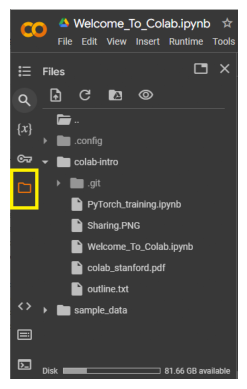

In [ ]:
# import matplotlib.pyplot as plt
# import matplotlib.image as mpimg

# img = mpimg.imread('colab-intro/Files.PNG')
# plt.imshow(img)
# plt.axis('off')
# plt.show()

## 1.9. Files (left upper)

- accessing external files
    - connecting to google drive
			from google.colab import drive
			drive.mount('/content/drive')
	- via github cloning
            !git clone url_ending__.git
	- saving files
		- to Google Drive
                once connected to google drive (Simply ctrl + s)
        - to GitHub
                File --> save to github

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls
!pwd

anscombe.json		      mnist_test.csv
california_housing_test.csv   mnist_train_small.csv
california_housing_train.csv  README.md
/content/sample_data


---
# 1. Setting up Environment

In this section we will:
- Install and import the libraries we need
- Confirm we have a GPU available
- Download the MNIST dataset and build a small subset
- Look at a few sample images


In [ ]:
# Install/upgrade the libraries used in this session.
# Most of these already ship with Google Colab, but we upgrade them here
# so that we have the latest versions in this exercise.
!pip install -q --upgrade transformers scikit-learn

In [ ]:
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Fix random seeds so that results are reproducible across runs and machines.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


## Checking for a GPU

Deep learning involves a huge number of repeated matrix multiplications. GPUs (Graphics Processing Units) are built to do exactly that kind of math in parallel, which makes them dramatically faster than a regular CPU for training and running neural networks. The cell below confirms Colab has handed us one.

This example is deliberately small, so having a GPU is optional.


In [ ]:
import sys
import torch

# Limit CPU threads for a fast, predictable classroom-sized example.
torch.set_num_threads(min(4, torch.get_num_threads()))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Selected device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("A GPU was not assigned; the demonstration will run on CPU.")

Python: 3.13.18
PyTorch: 2.14.1+cpu
Selected device: cpu
A GPU was not assigned; the demonstration will run on CPU.


## About the dataset: MNIST

[MNIST](https://en.wikipedia.org/wiki/MNIST_database) is a dataset of 70,000 grayscale images of handwritten digits (0–9), each 28×28 pixels. It has been a standard "hello world" benchmark for image classification for decades — small enough to train on quickly, but non-trivial enough to be a genuine test of a model's ability to recognize visual patterns.


In [ ]:
print("Downloading MNIST (this happens once and is cached locally)...")
mnist_train_full = datasets.MNIST(root="./data", train=True, download=True)
mnist_test_full = datasets.MNIST(root="./data", train=False, download=True)

print(f"Full training set size: {len(mnist_train_full)} images")
print(f"Full test set size:     {len(mnist_test_full)} images")

100%|██████████| 9.91M/9.91M [00:00<00:00, 14.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 460kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.71MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.94MB/s]

Full training set size: 60000 images
Full test set size:     10000 images


## Building one shared subset for all three exercises

The full MNIST dataset has 70,000 images. To keep every exercise fast enough to run live, we'll work with a much smaller **class-balanced** slice: 600 training images and 100 test images *per digit* — 6,000 training images and 1,000 test images in total.

Importantly, **all three exercises use the same data slice**, ensuring that the final accuracy comparison is based on identical input data.

In [ ]:
def balanced_subset_indices(dataset, n_per_class, seed=SEED):
    """Return a list of dataset indices containing exactly n_per_class examples of each digit."""
    rng = np.random.default_rng(seed)
    targets = dataset.targets.numpy()
    indices = []
    for digit in range(10):
        digit_indices = np.where(targets == digit)[0]
        chosen = rng.choice(digit_indices, size=n_per_class, replace=False)
        indices.extend(chosen.tolist())
    rng.shuffle(indices)
    return indices

TRAIN_PER_CLASS = 600   # -> 6,000 training images total
TEST_PER_CLASS = 100    # -> 1,000 test images total

train_indices = balanced_subset_indices(mnist_train_full, TRAIN_PER_CLASS)
test_indices = balanced_subset_indices(mnist_test_full, TEST_PER_CLASS)

print(f"Shared training subset: {len(train_indices)} images (balanced across all 10 digits)")
print(f"Shared test subset:     {len(test_indices)} images (balanced across all 10 digits)")

Shared training subset: 6000 images (balanced across all 10 digits)
Shared test subset:     1000 images (balanced across all 10 digits)


In [ ]:
def dataset_subset_to_numpy(dataset, indices):
    """Pull a subset of a torchvision MNIST dataset into plain numpy arrays."""
    images = dataset.data[indices].numpy()      # shape: (N, 28, 28), pixel values 0-255
    labels = dataset.targets[indices].numpy()   # shape: (N,)
    return images, labels

train_images, train_labels = dataset_subset_to_numpy(mnist_train_full, train_indices)
test_images, test_labels = dataset_subset_to_numpy(mnist_test_full, test_indices)

print(f"train_images shape: {train_images.shape}, train_labels shape: {train_labels.shape}")
print(f"test_images shape:  {test_images.shape},  test_labels shape:  {test_labels.shape}")

train_images shape: (6000, 28, 28), train_labels shape: (6000,)
test_images shape:  (1000, 28, 28),  test_labels shape:  (1000,)


Let's look at a few of the images we'll be working with:

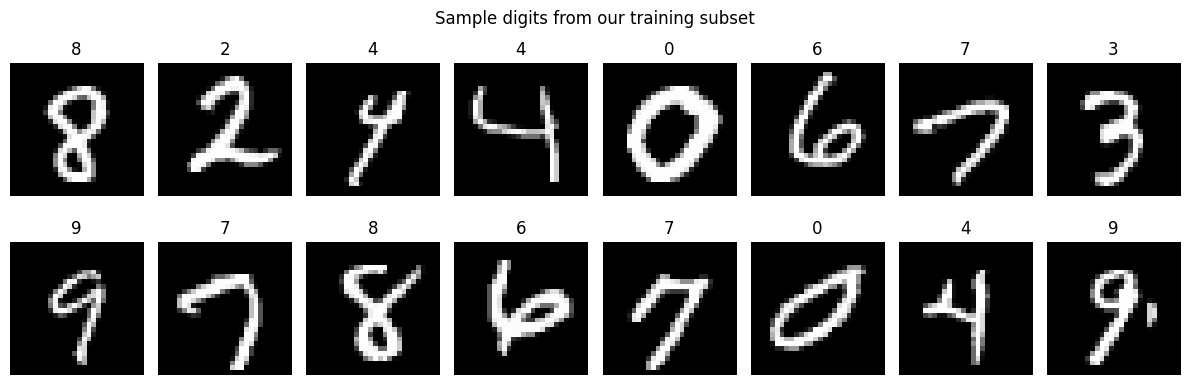

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(train_images[i], cmap="gray")
    ax.set_title(str(train_labels[i]))
    ax.axis("off")
plt.suptitle("Sample digits from our training subset")
plt.tight_layout(h_pad=3.0)
plt.show()

## A helper we'll use in our exercises

To evaluate our model let's write one confusion-matrix plotting function. A confusion matrix shows, for every true digit (rows), what the model actually predicted (columns) — the diagonal is correct predictions, everything off the diagonal is a mistake.

In [ ]:
def plot_confusion_matrix(y_true, y_pred, title):
    """Plot a 10x10 confusion matrix for digit predictions (0-9)."""
    cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xlabel("Predicted digit")
    ax.set_ylabel("True digit")
    ax.set_title(title)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

# We'll add one entry to this dictionary after each exercise.
results = {}

---
# 2. Multi-Layer Perceptron (MLP) with PyTorch

A **[Multi-Layer Perceptron](https://www.geeksforgeeks.org/deep-learning/multi-layer-perceptron-learning-in-tensorflow/)** is the simplest kind of deep neural network: a stack of layers, where each layer applies a linear transformation followed by a non-linear "activation function." That non-linearity is the key difference from Logistic Regression (which is essentially a single linear layer) — stacking non-linear layers lets the network learn much more complex, curved decision boundaries instead of a single straight-line-style separation between classes.

We'll build a network with the shape:

`784 pixels → 256 neurons → 128 neurons → 10 digit scores`

and **train** it — meaning we'll show it the training images repeatedly, measure how wrong its predictions are, and nudge its weights to be a little less wrong each time, using an algorithm called gradient descent.


![MLP](https://raw.githubusercontent.com/rochanaro/contemporary-ai-2026/refs/heads/main/figures/mlp.png)

### Step 1: Build PyTorch datasets and data loaders

PyTorch works with its own `Dataset` and `DataLoader` objects, which handle batching (grouping several images together) and shuffling automatically. `transforms.ToTensor()` converts each image from a 0–255 pixel-value image into a PyTorch tensor scaled to 0–1, in the shape PyTorch expects: `(channels, height, width)`.


In [ ]:
transform = transforms.ToTensor()

mnist_train_full_t = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
mnist_test_full_t = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Reuse the exact same indices as Exercise 1, so the training/test data matches exactly.
train_subset = Subset(mnist_train_full_t, train_indices)
test_subset = Subset(mnist_test_full_t, test_indices)

BATCH_SIZE = 64
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Number of training batches: {len(train_loader)} (batch size {BATCH_SIZE})")
print(f"Number of test batches:     {len(test_loader)}")

Number of training batches: 94 (batch size 64)
Number of test batches:     16


### Step 2: Define the model

- `nn.Flatten()` turns each 28×28 image into a 784-length vector (same idea as Exercise 1)
- `nn.Linear(in, out)` is a fully-connected layer: every input is connected to every output with a learnable weight
- `nn.ReLU()` is the activation function: it simply zeroes out negative values (`ReLU(x) = max(0, x)`). This small non-linearity, repeated across layers, is what gives neural networks their expressive power
- The final layer outputs 10 numbers (one "score" per digit); the highest score is the model's prediction


In [ ]:
class MLP(nn.Module):
    """A simple fully-connected neural network for digit classification."""

    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),              # (batch, 1, 28, 28) -> (batch, 784)
            nn.Linear(28 * 28, 256),   # first hidden layer
            nn.ReLU(),
            nn.Linear(256, 128),       # second hidden layer
            nn.ReLU(),
            nn.Linear(128, 10),        # output layer: one score per digit (0-9)
        )

    def forward(self, x):
        return self.layers(x)

mlp_model = MLP().to(device)
print(mlp_model)

n_params_mlp = sum(p.numel() for p in mlp_model.parameters())
print(f"\nTotal trainable parameters: {n_params_mlp:,}")

MLP(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total trainable parameters: 235,146


### Step 3: Define the loss function and optimizer

- **Loss function** (`CrossEntropyLoss`): measures how wrong the model's predictions are compared to the true labels. Lower is better.
- **Optimizer** (`Adam`): the algorithm that uses the loss to decide how to adjust every weight in the network, a little bit, after each batch.


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp_model.parameters(), lr=1e-3)

### Step 4: Train the model

One pass through the *entire* training set is called an **epoch**. For each batch of images in each epoch, the training loop does four things:
1. **Forward pass** — run the images through the network to get predictions
2. **Compute loss** — compare predictions to the true labels
3. **Backward pass** — compute how much each weight contributed to the error (`loss.backward()`)
4. **Update weights** — nudge every weight slightly to reduce the error (`optimizer.step()`)


In [ ]:
NUM_EPOCHS = 15
train_losses = []

start_time = time.time()

for epoch in range(NUM_EPOCHS):
    mlp_model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()          # reset gradients from the previous step
        outputs = mlp_model(images)    # forward pass
        loss = criterion(outputs, labels)
        loss.backward()                # backward pass: compute gradients
        optimizer.step()               # update the model's weights

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_subset)
    train_losses.append(epoch_loss)
    print(f"Epoch {epoch + 1:2d}/{NUM_EPOCHS} - training loss: {epoch_loss:.4f}")

train_time_mlp = time.time() - start_time
print(f"\nTotal training time: {train_time_mlp:.2f} seconds")

Epoch  1/15 - training loss: 0.8912
Epoch  2/15 - training loss: 0.3447
Epoch  3/15 - training loss: 0.2641
Epoch  4/15 - training loss: 0.2054
Epoch  5/15 - training loss: 0.1679
Epoch  6/15 - training loss: 0.1327
Epoch  7/15 - training loss: 0.1022
Epoch  8/15 - training loss: 0.0768
Epoch  9/15 - training loss: 0.0615
Epoch 10/15 - training loss: 0.0413
Epoch 11/15 - training loss: 0.0363
Epoch 12/15 - training loss: 0.0274
Epoch 13/15 - training loss: 0.0205
Epoch 14/15 - training loss: 0.0120
Epoch 15/15 - training loss: 0.0112

Total training time: 24.55 seconds


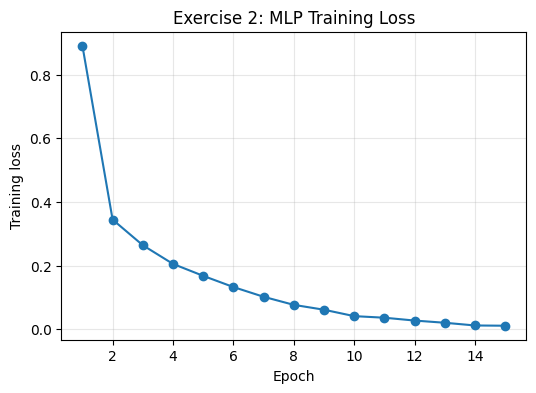

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, NUM_EPOCHS + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Exercise 2: MLP Training Loss")
plt.grid(alpha=0.3)
plt.show()

A steadily decreasing loss curve means the model is successfully learning from the training data. If you ever see the loss stop decreasing or start increasing, that's usually a sign the learning rate is too high, or the model needs more/less capacity.

### Step 5: Evaluate the model


Test accuracy: 94.40%
Inference time for 1000 images: 0.154 seconds


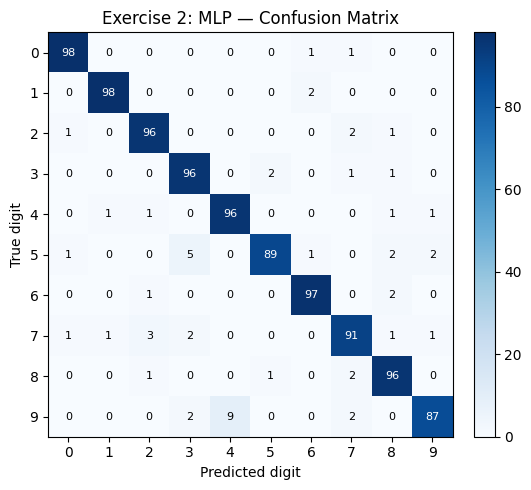

In [ ]:
mlp_model.eval()
all_preds = []
all_labels = []

start_time = time.time()
with torch.no_grad():  # we don't need gradients for evaluation, this saves memory and time
    for images, labels in test_loader:
        images = images.to(device)
        outputs = mlp_model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
inference_time_mlp = time.time() - start_time

accuracy_mlp = accuracy_score(all_labels, all_preds)
print(f"Test accuracy: {accuracy_mlp * 100:.2f}%")
print(f"Inference time for {len(all_labels)} images: {inference_time_mlp:.3f} seconds")

plot_confusion_matrix(all_labels, all_preds, "Exercise 2: MLP — Confusion Matrix")

results["MLP (PyTorch)"] = {
    "Training required": "Yes",
    "Training time (s)": round(train_time_mlp, 2),
    "Inference time (s)": round(inference_time_mlp, 3),
    "Test accuracy": round(accuracy_mlp, 4),
    "Parameters": n_params_mlp,
}